# STEP 1 - General description of the sector

| Question to answer (Presentation deck, Step 1) | How we measure it in this notebook |
|---|---|
| How big is the field, and is it growing, flat or declining? | Families/patent applications per earliest priority year/appliation year and applications per filing year; growth (%) of the sector compared with the growth (%) of all patents |
| Which technologies make up the field? Which classes dominate, and how is the mix shifting? | Fractional counts by CPC subclass, and by WIPO technology field, over time |
| Where is it happening? | Filing offices (IP5); applicant and inventor countries (fractional counts) |
| Is the field patent-heavy, or does it rely on secrecy? | Compare, for instance, with a similar field |

## 1. Setup and configuration

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

Our sector pool is **Quantum Computing**: we search the CPC codes over the scheme (https://www.cooperativepatentclassification.org) and validate them.

### 1.1 Sector definition: Quantum Computing

Our sector from the pool is **Quantum Computing** (client: **Dell**).

**Strategy (Step 0).** A patent family belongs to the sector if it matches **CPC codes** OR **keywords** in the title/abstract:

$$\text{Quantum} = \text{CPC} \cup \text{Keywords}$$

- **CPC codes**: chosen by reading the official scheme ([cooperativepatentclassification.org](https://www.cooperativepatentclassification.org)). We keep the core quantum-computing group (`G06N10`) and a few relevant codes
- **Keywords**: terms specific to quantum computing. 


In [2]:
# ---------------------------------------------------------------- environment
#ENV = "TEST"                 # develop on TEST (fast, ~10K publications)
ENV = "PROD"                  # full PATSTAT: every number in the deck comes from here
OUTPUT_DIR = Path("outputs/step1")  

# ---------------------------------------------------------------- sector definition
SECTOR_NAME = "Quantum Computing"

# CPC codes: a family is in the sector if any of its CPC symbols starts with one of these.
# Matching is by prefix (blanks removed), so "G06N10" also selects all its subgroups.
SECTOR_CPC_PREFIXES = (
    
    "G06N10/00", # Quantum computing
    "G06N10/20", # Models of quantum computing
    "G06N10/40", # Physical realisations or architectures of quantum processors or components for manipulating qubits
    "G06N10/60", # Quantum algorithms
    "G06N10/70", # Quantum error correction, detection or prevention
    "G06N10/80", # Quantum programming
    # B82Y10/00 (nanotechnology for information processing) was removed from the
    # definition on 17 Oct. Counted on its own it holds 96% of our year-2000
    # families, falls 89% from its 2004 peak to its 2014 trough, and compounds at
    # zero across the whole window: it contributed the entire decline-and-recovery
    # shape of the volume curve and none of the trend. Genuine quantum-nanotech
    # families still enter through the keyword branch. See Section 7.3.
    # "B82Y10/00",
    "H04B10/70", # Photonic quantum communication 
    "H04L9/0852", # Quantum key distribution
    "H10N60/12" # Josephson-effect devices, the base of superconducting qubits
)

# Keywords searched (case-insensitive) in titles and abstracts, OR-ed with the CPC codes.

SECTOR_KEYWORDS = (
    "quantum comput",            # also matches "quantum computing/computer(s)"
    "qubit", "qbit", "quantum bit",
    "quantum gate", "quantum logic gate", "quantum circuit", "quantum register",
    "quantum algorithm", "quantum annealing", "quantum annealer",
    "quantum error correction",
    "quantum supremacy", "quantum advantage",
    "quantum processor", "quantum processing unit",
    "transmon", "superconducting qubit", "trapped ion qubit",
    "topological qubit", "spin qubit", "photonic qubit",
)

# ---------------------------------------------------------------- time window 
YEAR_MIN, YEAR_MAX = 2000, 2022 
# we fix 2022 as max year since applications are published 18 months after the priority date and even later on the PATSAT platform
# so the last ~3 filing or priority years are incomplete.

# Which year to use (see Section 3). Three columns of tls201_appln can date a patent:
#   "appln_filing_year"    year this application was filed
#   "earliest_publn_year"  year of the first publication
#   "earliest_filing_year" earliest priority year (first filing of the invention, anywhere)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: the earliest one in the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only (excludes utility models "UM")
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices (Section 9)
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived values
LAST_COMPLETE_YEAR = YEAR_MAX
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# PATSTAT client (ENV chosen above) and SQLAlchemy session used by every query
patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: Quantum Computing | env: PROD | years 2000-2022 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


## 2. Analysis of applications and families

**An application (`appln_id`)** is one request for protection filed at one patent office. Each row of `tls201_appln` is an application, identified by `appln_id`. The office is in `appln_auth` (e.g. `EP` = European Patent Office, `US`, `CN`, `IT`, and `WO` for an international application filed through the PCT, see Section 4).

**A family (`docdb_family_id`)** groups all the applications that protect the **same invention** in different offices. A patent is valid only in the country that grants it: to be protected in several countries, an applicant files the same invention in several offices, and each filing becomes a separate application. PATSTAT links them with the same `docdb_family_id`.



| | Application level (`appln_id`) | Family level (`docdb_family_id`) |
|---|---|---|
| What one unit is | a filing at one office | an invention |
| Answers questions like | How much protection is sought, and where? | How many inventions are produced, by whom, in which technologies? |
| Watch out | an invention filed in many offices counts many times | each invention counts once |
| Year used here | the application's filing year | the earliest priority year of the family |

Either the  **family or application id could be the reference units for the PW** (one invention = one count). In this notebook every plot is shown at **both levels**, side by side, so you can see how much the picture changes.

The sector is always selected at family level: a family belongs to the sector if any of its applications has one of the sector CPC codes. At application level we then count all the applications of those families. So the two levels look at the same patents and differ only in *how we count*.

### 2.1 Selecting the sector

In [3]:
# These are just examples you can write your own functions with your own rules

def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition(terms):
    """OR-condition: any term appears in the title or abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))


def sector_family_ids(cpc_prefixes=SECTOR_CPC_PREFIXES, keywords=SECTOR_KEYWORDS):
    """Query of the docdb_family_ids that belong to the sector (CPC codes OR keywords)."""
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    by_cpc = (
        db.query(family_id)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes))
    )
    if not keywords:
        return by_cpc.distinct()
    by_keywords = (
        db.query(family_id)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(keywords))
    )
    return by_cpc.union(by_keywords)   # UNION removes duplicates


sector_ids = sector_family_ids()

### 2.1.1 How large is the definition?

`sector_family_ids()` returns a *query*, not a result: nothing has been counted
yet. Before building anything on top of it we execute the three branches
separately, because the composition of the union is itself a finding.

A keyword branch far larger than the CPC branch would mean the free-text terms
are over-reaching; a CPC branch dominated by the communication codes would mean
our sector is, in substance, quantum communication. Both are reported in the
technical appendix.

In [4]:
def n_families(q, label):
    """Execute a family-id query and report how many distinct families it returns."""
    sq = q.distinct().subquery()
    n = patstat.df(db.query(func.count(distinct(sq.c.docdb_family_id)).label("n"))).loc[0, "n"]
    print(f"{label:<26} {n:>12,}")
    return n


fid = TLS201_APPLN.docdb_family_id.label("docdb_family_id")

branch_cpc = (
    db.query(fid)
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES))
)
branch_kw = (
    db.query(fid)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .filter(keyword_condition(SECTOR_KEYWORDS))
)

n_families(branch_cpc,  "CPC branch")
n_families(branch_kw,   "Keyword branch")
n_families(sector_ids,  "UNION (the sector)")

CPC branch                       20,024
Keyword branch                   11,599
UNION (the sector)               23,492


np.int64(23492)

### 2.2 One real family, application by application

Let us look at the sector family with the most applications. Each row is one `appln_id`; they all share the same `docdb_family_id`.

In [5]:
n_applications = func.count(TLS201_APPLN.appln_id)
largest_family = (
    db.query(TLS201_APPLN.docdb_family_id, n_applications.label("n_applications"))
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .order_by(n_applications.desc())
    .limit(1)
)
example_family_id = int(patstat.df(largest_family).loc[0, "docdb_family_id"])

example_family = patstat.df(
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
    )
    .filter(TLS201_APPLN.docdb_family_id == example_family_id)
    .order_by(TLS201_APPLN.appln_filing_date)
)
example_family

,docdb_family_id,appln_id,appln_auth,appln_kind,appln_filing_date,appln_filing_year,earliest_publn_year,earliest_filing_year,granted,docdb_family_size
0,84360761,590379869,DE,A,2022-10-07,2022,2023,2021,N,69
1,84360761,592728943,DE,A,2022-10-10,2022,2023,2021,N,69
2,84360761,590380953,DE,A,2022-10-10,2022,2023,2021,N,69
3,84360761,590382320,DE,A,2022-10-10,2022,2023,2021,N,69
4,84360761,590380783,DE,A,2022-10-10,2022,2023,2021,N,69
...,...,...,...,...,...,...,...,...,...,...
64,84360761,590379974,DE,A,2022-10-27,2022,2023,2021,N,69
65,84360761,590379910,DE,A,2022-10-27,2022,2023,2021,N,69
66,84360761,590379902,DE,A,2022-10-27,2022,2023,2021,N,69
67,84360761,590382110,DE,A,2022-10-27,2022,2023,2021,N,69


### Brief analysis of the extracted family 

#### TEST environment (earlier run, retained for comparison)

The paragraph below records what this same query returned on the reduced TEST
dataset. The output shown above is from PROD; the two are not comparable and the
TEST figures are kept only to illustrate how much the sample size matters.
The output table above displays an example of a single patent family (`docdb_family_id` = 85384162) extracted from our target sector in which all applications were filed in Germany. Since we are operating in the `TEST` environment (a restricted subset of PATSTAT data), this is the largest family found within this limited dataset, consisting of 6 applications.

* We can observe the difference between an **application** and a **family**: all rows share the same `docdb_family_id`, meaning they all protect the exact same underlying invention. However, they have different `appln_id` values, representing distinct filings. 
* We can also distinguish between patent applications (`appln_kind` = 'A', currently not granted, `granted` = 'N') and utility models (`appln_kind` = 'U', which have been granted, `granted` = 'Y'). Utility models are a shorter, blended version of a design and a patent. 
*   The `earliest_filing_year` (the priority year, 2022 in this case) is identical for the entire family and represents the first date of filing.

#### PROD Environment 

By switching to the `PROD` environment, we retrieve the full PATSTAT dataset. The largest patent family in our Quantum Computing sector (`docdb_family_id` = 29424519) contains **98 applications**.

This illustrates the difference between counting inventions (families) and counting patent filings (applications):
*   **1 single invention** was originally conceived and protected with an earliest priority filing in **2002**.
*   Between **2003 and 2006**, the applicant pursued international protection, resulting in **98 separate application filings** across multiple global patent offices.

This geographical extension highlights the strategic value the applicant placed on this specific quantum technology, willing to sustain the high costs of global patent prosecution.


## 3. Three ways to date a patent: time dimension

Each application in `tls201_appln` carries three years. The same invention can therefore be placed in different years depending on the column you choose.

| Column | What it is | Use it when… | Incomplete recent years |
|---|---|---|---|
| `appln_filing_year` | year **this application** was filed at its office | you count applications | ~3 years (applications become visible only after publication, ~18 months) |
| `earliest_publn_year` | year of the **first publication** of the application | you want the most up-to-date series (EPO statistics use it) | only the current year |
| `earliest_filing_year` | year of the **earliest priority**: the first filing of the invention anywhere in the world | you want the date closest to the invention | ~3 years |

At **family level** we need one year per family: we take the **smallest `earliest_filing_year`** among its applications, i.e. the first time the invention was filed anywhere (PW rule). At **application level** we use the application's own `appln_filing_year`. Both choices can be changed in the configuration (`FAMILY_TIME_COLUMN`, `APPLN_TIME_COLUMN`).


On our example family:

In [6]:
years = example_family[["appln_id", "appln_auth", "appln_filing_year", "earliest_publn_year", "earliest_filing_year"]]
family_year = example_family["earliest_filing_year"].min()
print(f"Family {example_family_id}: {len(example_family)} applications filed between "
      f"{example_family['appln_filing_year'].min()} and {example_family['appln_filing_year'].max()}; "
      f"family year (earliest priority) = {family_year}")
years

Family 84360761: 69 applications filed between 2022 and 2025; family year (earliest priority) = 2021


,appln_id,appln_auth,appln_filing_year,earliest_publn_year,earliest_filing_year
0,590379869,DE,2022,2023,2021
1,592728943,DE,2022,2023,2021
2,590380953,DE,2022,2023,2021
3,590382320,DE,2022,2023,2021
4,590380783,DE,2022,2023,2021
...,...,...,...,...,...
64,590379974,DE,2022,2023,2021
65,590379910,DE,2022,2023,2021
66,590379902,DE,2022,2023,2021
67,590382110,DE,2022,2023,2021


At application level this family adds one count to each of the filing years above;
at family level it adds a single count, to its priority year. Section 7.1 shows the
effect of this choice on the sector as a whole.

Our PROD example makes the contrast concrete: a single invention, counted **once**
in 2002 at family level, contributes **98** counts spread over 2003-2006 at
application level. Any statement about "how much patenting happens in year *t*"
is therefore meaningless until the counting unit is fixed.

## 4. Other methodological choices

These choices are the same for every number in the notebook. State them in the technical appendix of your deck.

**Truncation.** Applications are published some 18 months after the priority date
and reach PATSTAT later still, so the most recent priority years are structurally
incomplete. Rather than plotting incomplete years and shading them, we close the
observation window at 2022, the last year we treat as complete, so that no incomplete
year is drawn at all. A fall in the final years of a raw PATSTAT series is an artefact
of publication lag, not a decline in inventive activity, and closing the window removes
the possibility of reading one for the other. Section 7.1 shows the coverage frontier
that justifies the cut-off.

**International applications through the PCT.** The Patent Cooperation Treaty (PCT) lets an applicant file **one international application**, handled by WIPO, that can later be extended to more than 150 countries. In PATSTAT it has `appln_auth = 'WO'` and `appln_kind` starting with `W`. Filing through the PCT costs money, so it signals an invention the applicant wants to protect abroad.

| | Family level | Application level |
|---|---|---|
| "via PCT" means… | the family has at least one PCT application | the application is itself a PCT application |

**Fractional counting.** In this code, when a family has applicants from different countries, each country receives a fraction of the family, proportional to its number of distinct applicants. For example, a family with 2 Italian applicants and 1 German applicant counts 2/3 for IT and 1/3 for DE. Each family then sums to exactly 1. The same rule applies to inventors and to technology classes: a family in 4 CPC subclasses gives 1/4 to each. At application level the same rule splits each application.

## 5. Tables and attributes used in Step 1

All tables join on `appln_id` (application level), except `tls206_person`, which joins `tls207_pers_appln` on `person_id`.

| Table | Grain (one row per…) | Attributes used | Used for |
|---|---|---|---|
| `tls201_appln` | application | `appln_id` (application key), `docdb_family_id` (family key), `appln_auth` (office), `appln_kind`, `ipr_type`, `appln_filing_year`, `earliest_publn_year`, `earliest_filing_year`, `granted`, `docdb_family_size` | the two levels, the three years, offices, PCT, grant rate, family size |
| `tls224_appln_cpc` | application × CPC symbol | `cpc_class_symbol` | sector definition; CPC subclass mix |
| `tls202_appln_title`, `tls203_appln_abstr` | application | `appln_title`, `appln_abstract` | optional keyword part of the sector definition |
| `tls207_pers_appln` | application × person × role | `person_id`, `applt_seq_nr` (> 0: applicant), `invt_seq_nr` (> 0: inventor) | who is an applicant, who is an inventor |
| `tls206_person` | person | `person_ctry_code`, `psn_name`, `psn_sector` | applicant and inventor countries; names for Step 2 |
| `tls230_appln_techn_field` | application × technology field | `techn_field_nr` (1–35), `weight` (sums to 1 per application) | WIPO technology fields |
| `tls901_techn_field_ipc` | IPC main group | `techn_field_nr`, `techn_field`, `techn_sector` | names of the 35 fields and of the 5 technology sectors |

Things to know about these attributes:

- `cpc_class_symbol` is padded with blanks (`F03B  13/14`): we strip blanks before matching, as in Tutorial 0. The **subclass** is the first 4 characters (`F03B`).
- `appln_kind` is a 2-character field (`'A '`), so `appln_kind == 'A'` fails: use `LIKE 'A%'`.
- `person_ctry_code` can be **empty (`''`) as well as `NULL`**: both are treated as unknown and excluded from country counts (their number is reported).
- The same real applicant can appear under several `person_id`s. Fractional counts are computed on distinct `person_id`s; name harmonisation (`psn_name`, `han_name`) is the topic of Step 2.

## 6. Some other examples to look at

### 6.1 Scopes

A **scope** is a query with one row per counting unit (`unit_id`) and its `year`:

- at **family level**, `unit_id` is the `docdb_family_id` and `year` is the family's earliest priority year;
- at **application level**, `unit_id` is the `appln_id` and `year` is its filing year.

We build four scopes, {family, application} × {all patents, sector}. "All patents" is the benchmark: the sector is compared with it. All calculations run inside the database, and only small result tables are downloaded.

In [7]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents)."""
    if family_ids is None:
        return q
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family, dated by its earliest priority year."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or the sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


SCOPES = [
    Scope("all patents", "family",      family_scope()),
    Scope(SECTOR_NAME,   "family",      family_scope(sector_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME,   "application", application_scope(sector_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application

### 6.2 Counting functions

Each function takes a scope and returns a small `DataFrame` carrying the columns
`scope` and `level`, so results from different scopes can be concatenated and then
filtered. Counts appear as `n` (whole units) or `n_frac` (fractional units).

On fractional counting: when a unit belongs to several categories, a family
classified in four CPC subclasses or filed by applicants from three countries, it
is split equally among them so that each unit contributes exactly 1 in total.
Without this rule a breakdown by category sums to more than the number of units,
and every share is overstated.

In [8]:
def _join_applications(q, scope):
    """Join each unit to its applications: all members of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Units per year; only_pct keeps those filed through the PCT."""
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories."""
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_country(scope, role="applicant", count_unknown=False):
    """Fractional counts by person country and year (role: 'applicant' or 'inventor')."""
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    raw_ctry = func.trim(TLS206_PERSON.person_ctry_code)   # unknown countries are NULL, '' or blanks

    if count_unknown:
        ctry = func.coalesce(
            func.nullif(raw_ctry, ""),
            "Unknown" # counting unknown countries 
        )
        country_filter = seq_nr > 0
    else:
        ctry = raw_ctry
        country_filter = (
            (seq_nr > 0)
            & raw_ctry.isnot(None)
            & (raw_ctry != "") # deleting unkonown countries
        )
        
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(country_filter)
        .subquery()
    )
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (the first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year.

    tls230 weights sum to 1 per application; at family level they are rescaled
    so that every family also sums to 1.
    """
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year.

    Family level: families with at least one application at the office.
    Application level: applications filed at the office.
    """
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    """Units, units via PCT, granted units and mean family size."""
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)

### 6.3 Caching and presentation helpers

Two small concerns, grouped here because neither belongs with the queries above.

**Caching.** The "all patents" scopes aggregate every family in PATSTAT and are
the most expensive cells in this notebook. Each result is therefore written to
`OUTPUT_DIR` the first time it is produced and read back from disk afterwards, so
that a lost kernel costs seconds rather than a working session. These are small
aggregates and are safe to version: it is the bulk PATSTAT extract that must not
be committed, not these.

**Truncation, and why nothing is shaded.** Section 4 explains why the window
closes at the last complete year rather than plotting incomplete years and marking
them. `shade_truncated` is kept and guarded accordingly: it does nothing while
`LAST_COMPLETE_YEAR` equals `YEAR_MAX`, and widening the window restores the
shading without any other edit.

In [9]:
def cached(name, build, force=False):
    """Compute build() once, then serve it from disk. Pass force=True to recompute."""
    path = OUTPUT_DIR / f"{name}.pkl"
    if path.exists() and not force:
        df = pd.read_pickle(path)
        print(f"[cache] {name:<22} {len(df):>8,} rows")
        return df
    df = build()
    df.to_pickle(path)
    print(f"[query] {name:<22} {len(df):>8,} rows")
    return df


def shade_truncated(ax):
    """Shade incomplete years; a no-op while the window ends at the last complete year."""
    if LAST_COMPLETE_YEAR >= YEAR_MAX:
        return
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages summing to 100 per column, 'Other' last, with a Total row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # grey reserved for "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

## 7. Volume: how big is the sector, and is it growing?

The client's first question, how is the sector doing overall, is answered here.
We count the sector's families and applications per year, separate those filed
through the PCT, and compare the sector's growth with the growth of patenting as
a whole.

The gap between the two curves is itself informative: it is the average number of
applications filed per invention, and therefore a measure of how widely applicants
in this sector seek protection.

[cache] volume                      184 rows


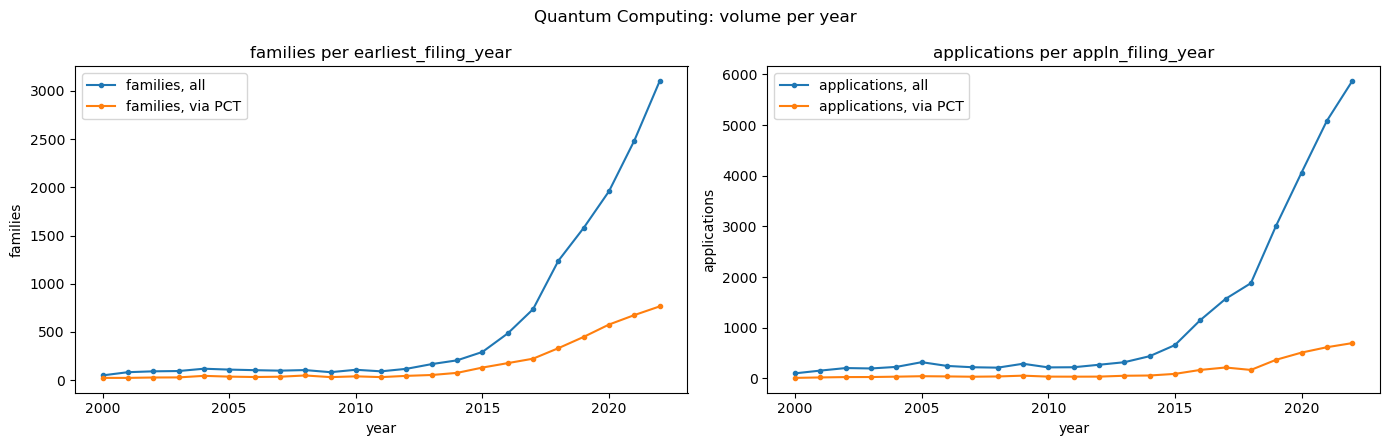

In [10]:
volume = cached(
    "volume",
    lambda: pd.concat(
        [count_per_year(s).assign(series="all") for s in SCOPES]
        + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
        ignore_index=True,
    ),
)

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    for series, grp in data.groupby("series"):
        ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_volume.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.1 The same inventions, dated three ways

`tls201_appln` carries three years, and the same patent falls in a different year
depending on which is used. Dating by **publication** shifts the curve some 18
months to the right and makes recent years look complete; dating by **priority**
places an invention at its origin, the date closest to the act of inventing; the
**family** curve lies below both, because each invention is counted once rather
than once per office.

The figure also documents our cut-off. The point at which each series collapses is
the coverage frontier of this PATSTAT edition, not a decline in patenting, and it
is the evidence behind closing the window where Section 4 closes it.

[query] dating                       92 rows


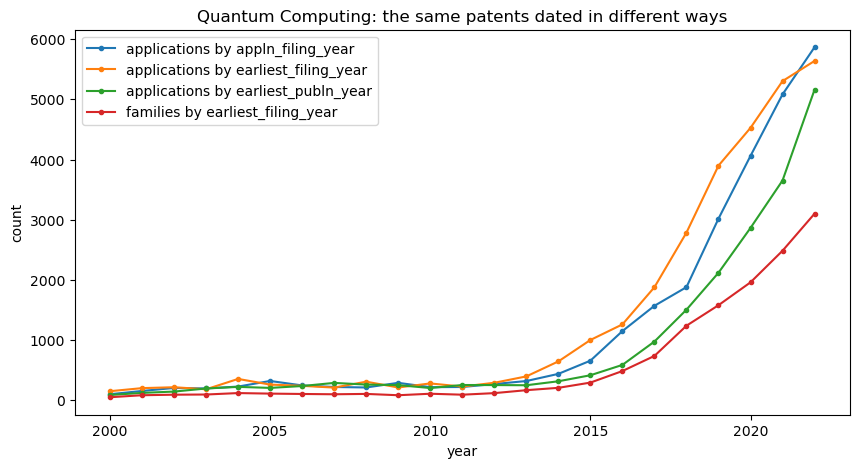

In [11]:
def _dating_series():
    by_col = [
        count_per_year(Scope(SECTOR_NAME, "application", application_scope(sector_ids, col)))
        .assign(series=f"applications by {col}")
        for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
    ]
    fam = volume[(volume["scope"] == SECTOR_NAME)
                 & (volume["level"] == "family")
                 & (volume["series"] == "all")].assign(series=f"families by {FAMILY_TIME_COLUMN}")
    return pd.concat(by_col + [fam], ignore_index=True)


dating = cached("dating", _dating_series)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.legend()
plt.savefig(OUTPUT_DIR / "fig_dating.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.2 Growth: faster or slower than patenting as a whole?

Patenting grows over time, so a sector that grows is not thereby remarkable. The
comparison that matters is relative: a sector growing +150% while all patents grow
+60% is **gaining weight** in technology; one growing +20% over the same period is
expanding in absolute terms while **losing ground**.

Two cautions apply with particular force to a young sector.

**Endpoint sensitivity.** Growth measured between two years is a ratio of two
single observations. Where the base year is small, and in the early 2000s this
sector is small, that ratio is dominated by noise. We therefore report the
end-point growth, the compound annual rate, and the same figures computed from a
later base year, and we read the curve rather than the headline number.

**Composition.** The series pools the quantum-computing classes with the
quantum-communication classes admitted by our query. The two have different filing
dynamics, so the aggregate rate is a weighted average of two distinct phenomena.
Section 8 separates them.

In [12]:
ALT_BASE_YEAR = 2010        # later base, for a sector whose early counts are thin

totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")
rows = [(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]


def growth_block(start, end):
    return pd.DataFrame({
        f"count {start}": totals.loc[start],
        f"count {end}": totals.loc[end],
        f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
        f"CAGR {start}-{end} (%)": ((totals.loc[end] / totals.loc[start]) ** (1 / (end - start)) - 1) * 100,
    }).loc[rows]


growth = growth_block(YEAR_MIN, LAST_COMPLETE_YEAR).join(
    growth_block(ALT_BASE_YEAR, LAST_COMPLETE_YEAR)[
        [f"growth {ALT_BASE_YEAR}-{LAST_COMPLETE_YEAR} (%)",
         f"CAGR {ALT_BASE_YEAR}-{LAST_COMPLETE_YEAR} (%)"]
    ]
)
growth.to_csv(OUTPUT_DIR / "tab_growth.csv")
growth.style.format({c: ("{:,.0f}" if c.startswith("count") else "{:+.1f}%") for c in growth.columns})

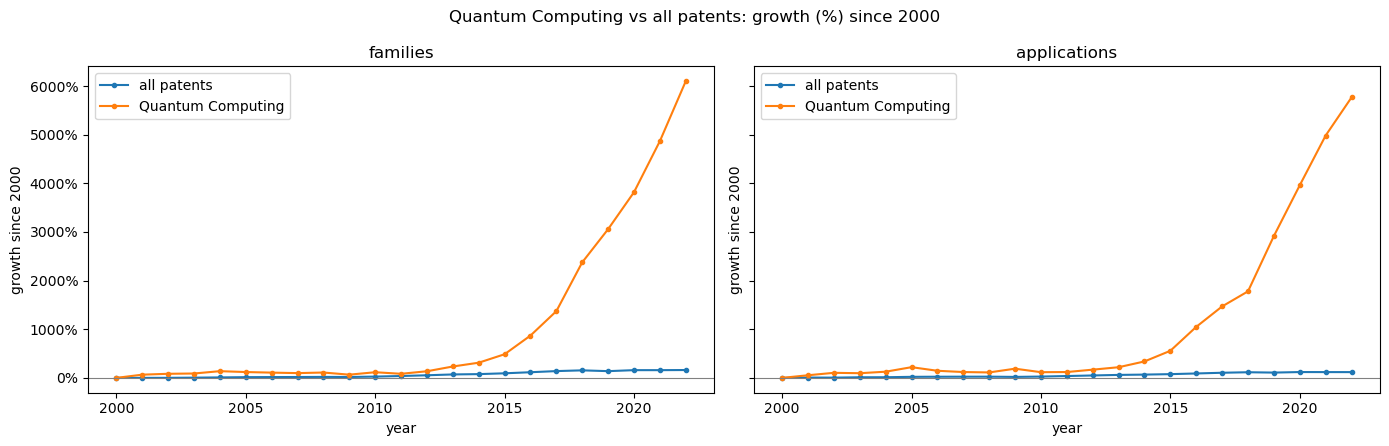

In [13]:
start, end = YEAR_MIN, LAST_COMPLETE_YEAR
growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = side_by_side(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", sharey=True)
for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(growth_path.index, growth_path[(level, scope_name)], marker="o", ms=3, label=scope_name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_growth.png", dpi=200, bbox_inches="tight")
plt.show()

[query] blocks                       92 rows


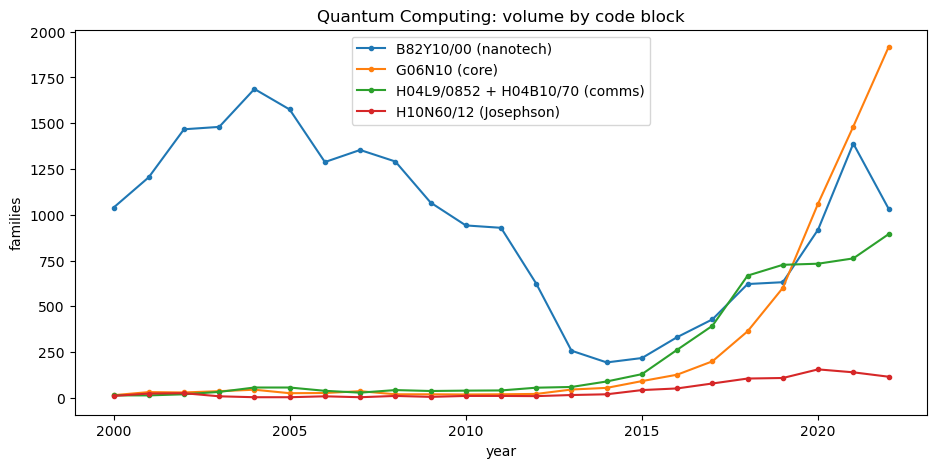

In [14]:
BLOCKS = {
    "G06N10 (core)":        ("G06N10",),
    "B82Y10/00 (nanotech)": ("B82Y10/00",),
    "H10N60/12 (Josephson)":("H10N60/12",),
    "H04L9/0852 + H04B10/70 (comms)": ("H04L9/0852", "H04B10/70"),
}

def block_series(prefixes):
    ids = (db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
           .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
           .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, prefixes))
           .distinct())
    return count_per_year(Scope(SECTOR_NAME, "family", family_scope(ids)))

blocks = cached("blocks", lambda: pd.concat(
    [block_series(p).assign(block=name) for name, p in BLOCKS.items()],
    ignore_index=True))

fig, ax = plt.subplots(figsize=(11, 5))
for name, g in blocks.groupby("block"):
    ax.plot(g["year"], g["n"], marker="o", ms=3, label=name)
ax.set(title=f"{SECTOR_NAME}: volume by code block", xlabel="year", ylabel="families")
ax.legend()
plt.savefig(OUTPUT_DIR / "fig_blocks.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
LEGACY = ("G06N99/002",)
leg = block_series(LEGACY).assign(block="G06N99/002 (legacy scheme)")
core = blocks[blocks["block"].str.contains("G06N10")]
chk = pd.concat([core, leg], ignore_index=True).pivot_table(
    index="year", columns="block", values="n", aggfunc="sum", fill_value=0)
print(chk.to_string())

block   G06N10 (core)
year                 
2000.0           15.0
2001.0           32.0
2002.0           30.0
2003.0           37.0
2004.0           45.0
2005.0           26.0
2006.0           27.0
2007.0           37.0
2008.0           20.0
2009.0           20.0
2010.0           19.0
2011.0           20.0
2012.0           22.0
2013.0           46.0
2014.0           55.0
2015.0           92.0
2016.0          127.0
2017.0          200.0
2018.0          364.0
2019.0          601.0
2020.0         1061.0
2021.0         1482.0
2022.0         1915.0


In [16]:
print(blocks.pivot_table(index="year", columns="block", values="n", aggfunc="sum", fill_value=0).to_string())

block  B82Y10/00 (nanotech)  G06N10 (core)  H04L9/0852 + H04B10/70 (comms)  H10N60/12 (Josephson)
year                                                                                             
2000                   1039             15                              14                     11
2001                   1205             32                              14                     24
2002                   1467             30                              20                     26
2003                   1480             37                              33                      9
2004                   1687             45                              57                      4
2005                   1575             26                              57                      4
2006                   1288             27                              39                      9
2007                   1354             37                              29                      4
2008                

## 8. Technology mix

### 8.1 CPC subclasses

Which subclasses dominate the sector, and how is the mix shifting? Each family (or application) is split equally across its CPC subclasses, so the shares sum to 100%. Many subclasses are co-classifications: a quantum computing family is often also classified in, for example, cryptography or semiconductor devices. They show which neighbouring technologies the sector draws on.


In [17]:
CPC_DEFINITIONS = {
    "G06N": "COMPUTING ARRANGEMENTS BASED ON SPECIFIC COMPUTATIONAL MODELS",
    "H04L": "TRANSMISSION OF DIGITAL INFORMATION, e.g. TELEGRAPHIC COMMUNICATION",
    "H04B": "TRANSMISSION",
    "G06F": "ELECTRIC DIGITAL DATA PROCESSING",
    "H10N": "ELECTRIC SOLID-STATE DEVICES NOT OTHERWISE PROVIDED FOR",
    "B82Y": "SPECIFIC USES OR APPLICATIONS OF NANOSTRUCTURES; MEASUREMENT OR ANALYSIS OF NANOSTRUCTURES; MANUFACTURE OR TREATMENT OF NANOSTRUCTURES",
    "Y02D": "CLIMATE CHANGE MITIGATION TECHNOLOGIES IN INFORMATION AND COMMUNICATION TECHNOLOGIES [ICT]",
    "G06Q": "INFORMATION AND COMMUNICATION TECHNOLOGY [ICT] SPECIALLY ADAPTED FOR ADMINISTRATIVE, COMMERCIAL, FINANCIAL, MANAGERIAL OR SUPERVISORY PURPOSES",
    "H03K": "PULSE TECHNIQUE",
    "H10D": "INORGANIC ELECTRIC SEMICONDUCTOR DEVICES",
    "Other": "other fields",
    "Total": ""
}

cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)
cpc_pooled = pd.concat([pool_other(cpc_mix[cpc_mix["level"] == lvl], "subclass").assign(level=lvl)
                        for lvl in LEVELS], ignore_index=True)

cpc_counts = complete_years(cpc_pooled).pivot_table(index="subclass", columns="level", values="n_frac",
                                                    aggfunc="sum", fill_value=0)[list(LEVELS)]
cpc_shares = share_table(cpc_counts)
cpc_shares["definition (fill in from the CPC scheme)"] = (cpc_shares.index.map(CPC_DEFINITIONS))
cpc_shares.style.format("{:.1f}%", subset=list(LEVELS))

level,family,application,definition (fill in from the CPC scheme)
subclass,,,
G06N,26.9%,26.1%,COMPUTING ARRANGEMENTS BASED ON SPECIFIC COMPUTATIONAL MODELS
H04L,23.7%,18.2%,"TRANSMISSION OF DIGITAL INFORMATION, e.g. TELEGRAPHIC COMMUNICATION"
H04B,10.5%,8.6%,TRANSMISSION
G06F,8.8%,9.6%,ELECTRIC DIGITAL DATA PROCESSING
H10N,4.5%,6.8%,ELECTRIC SOLID-STATE DEVICES NOT OTHERWISE PROVIDED FOR
B82Y,4.1%,6.5%,SPECIFIC USES OR APPLICATIONS OF NANOSTRUCTURES; MEASUREMENT OR ANALYSIS OF NANOSTRUCTURES; MANUFACTURE OR TREATMENT OF NANOSTRUCTURES
Y02D,1.9%,0.0%,CLIMATE CHANGE MITIGATION TECHNOLOGIES IN INFORMATION AND COMMUNICATION TECHNOLOGIES [ICT]
G06Q,1.3%,0.0%,"INFORMATION AND COMMUNICATION TECHNOLOGY [ICT] SPECIALLY ADAPTED FOR ADMINISTRATIVE, COMMERCIAL, FINANCIAL, MANAGERIAL OR SUPERVISORY PURPOSES"
H03K,0.0%,2.3%,PULSE TECHNIQUE


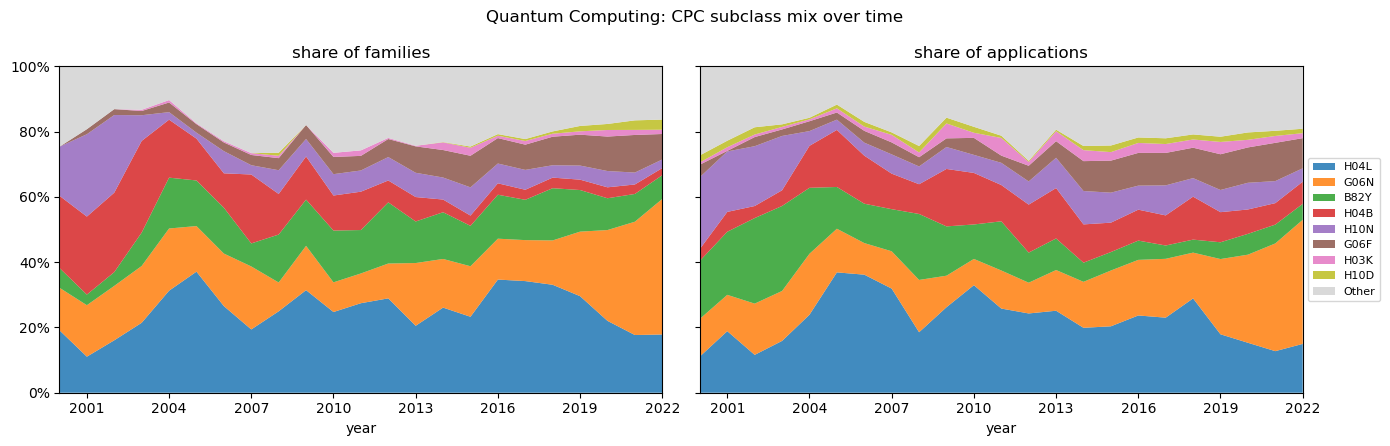

In [18]:
from matplotlib.ticker import MaxNLocator

fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
              f"share of {UNIT_LABEL[level]}")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

### 8.2 WIPO technology fields

WIPO groups all patents into **35 technology fields**, which belong to **5 technology sectors**: Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields (tables `tls230` + `tls901`). It is a coarser view than CPC, the same for every country and every sector.

The question is simple: **of 100 sector families, how many are in each technology sector?** The shares sum to 100%.

In [19]:
field_names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")

fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)

techn_sector_counts = complete_years(fields).pivot_table(index="techn_sector", columns="level", values="n_frac",
                                                         aggfunc="sum", fill_value=0)[list(LEVELS)]
techn_sector_shares = share_table(techn_sector_counts)
pct_format(techn_sector_shares)

level,family,application
techn_sector,,
Electrical engineering,90.8%,89.5%
Instruments,5.9%,6.3%
Chemistry,2.6%,3.3%
Mechanical engineering,0.6%,0.7%
Other fields,0.1%,0.1%
Total,100.0%,100.0%


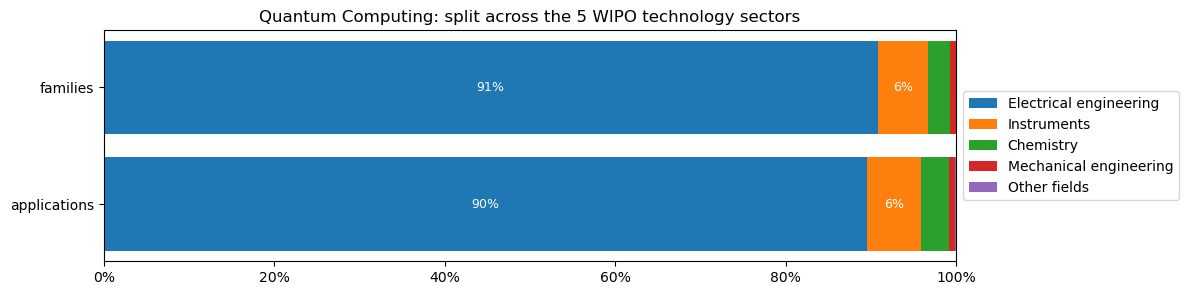

In [20]:
# One bar per level, split into the 5 technology sectors (each bar = 100%)
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

In [21]:
field_counts = complete_years(fields).pivot_table(index="techn_field", columns="level", values="n_frac",
                                                  aggfunc="sum", fill_value=0)[list(LEVELS)]
top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
pct_format(share_table(field_counts))

level,family,application
techn_field,,
Computer technology,40.7%,41.2%
Digital communication,24.4%,18.9%
Telecommunications,12.1%,10.1%
Semiconductors,8.5%,13.2%
Optics,2.8%,3.2%
Basic communication processes,2.4%,3.7%
Measurement,2.1%,2.2%
Micro-structural and nano-technology,1.7%,2.5%
Other,5.2%,5.0%


## 9. Geography

### 9.1 Filing offices: the IP5

The **IP5** are the five largest patent offices in the world, which together receive most of the world's patent applications:

| Code (`appln_auth`) | Office |
|---|---|
| `EP` | European Patent Office (EPO) |
| `US` | United States Patent and Trademark Office (USPTO) |
| `CN` | China National Intellectual Property Administration (CNIPA) |
| `JP` | Japan Patent Office (JPO) |
| `KR` | Korean Intellectual Property Office (KIPO) |

Where do applicants seek protection? Offices with many sector filings are the markets that applicants consider worth protecting.

- **Application level**: each application is filed at exactly one office, so we can split the sector's applications across offices and the shares sum to 100% (IP5, `WO` for PCT applications, and Other offices).
- **Family level**: one family is usually filed at several offices, so the office counts of a family overlap and **do not** sum to the number of families. We therefore show counts, not shares: "how many inventions are protected at each office".

In [22]:
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# Application level: shares across offices (sum to 100%)
office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
pct_format(office_shares)

Share of the sector's applications filed at the IP5: 74.7%


,applications
office,
CN,26.9%
US,25.3%
WO,12.5%
EP,10.0%
JP,8.1%
KR,4.4%
Other,12.8%
Total,100.0%


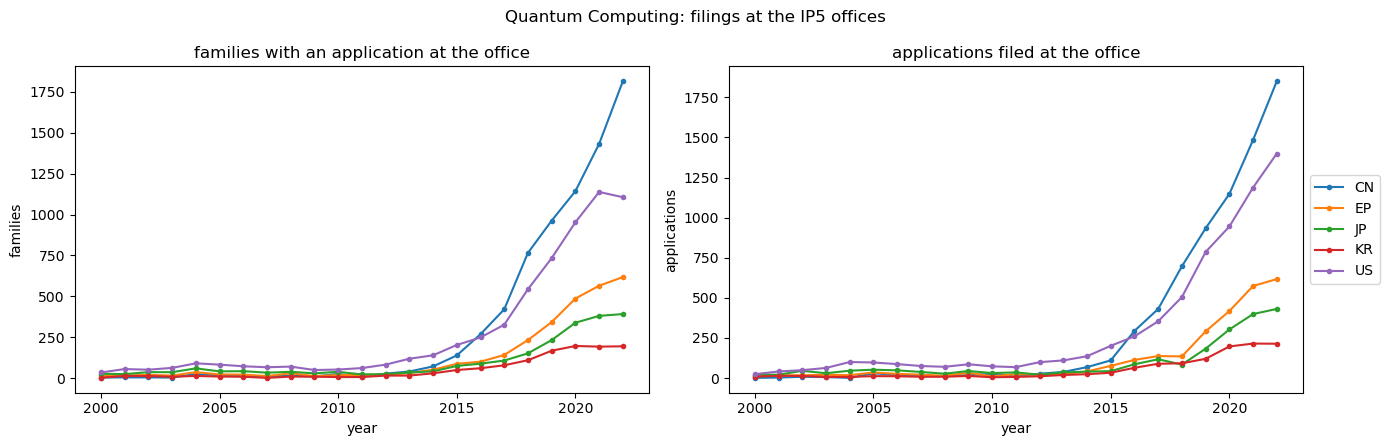

In [23]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family"
             else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

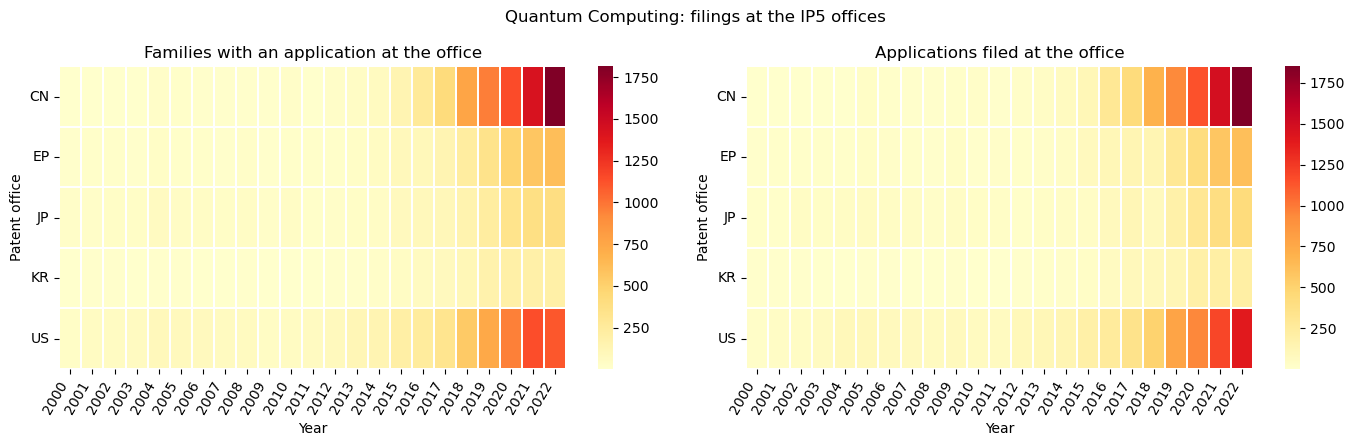

In [24]:
""" TODO: heatmap"""

import seaborn as sns

fig, axes = side_by_side(
    f"{SECTOR_NAME}: filings at the IP5 offices",
    sharex=True
)

for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")

    heatmap_data = data.pivot_table(
        index="office",
        columns="year",
        values="n",
        aggfunc="sum",
        fill_value=0
    )

    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap="YlOrRd",
        cbar=True,
        linewidths=0.2,
        linecolor="white"
    )

    title = (
        "Families with an application at the office"
        if level == "family"
        else "Applications filed at the office"
    )

    ax.set(
        title=title,
        xlabel="Year",
        ylabel="Patent office"
    )

    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    plt.setp(ax.get_yticklabels(), rotation=0, ha="right")
    
plt.tight_layout()
plt.show()

### 9.2 Applicant and inventor countries (fractional counts)

- **Applicant country**: where the *owners* of the technology are (which firms and countries control it).
- **Inventor country**: where the *research* is carried out.

A gap between the two (e.g. inventors in one country, applicants in another) may point to foreign R&D centres or acquisitions. Each column sums to 100%.

In [25]:
# counting countries without deleting unknown coountries

countries = pd.concat(
    [fractional_by_country(s, role, count_unknown=True) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts))

In [26]:
# counting countries after deleting unknown countries

countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts))

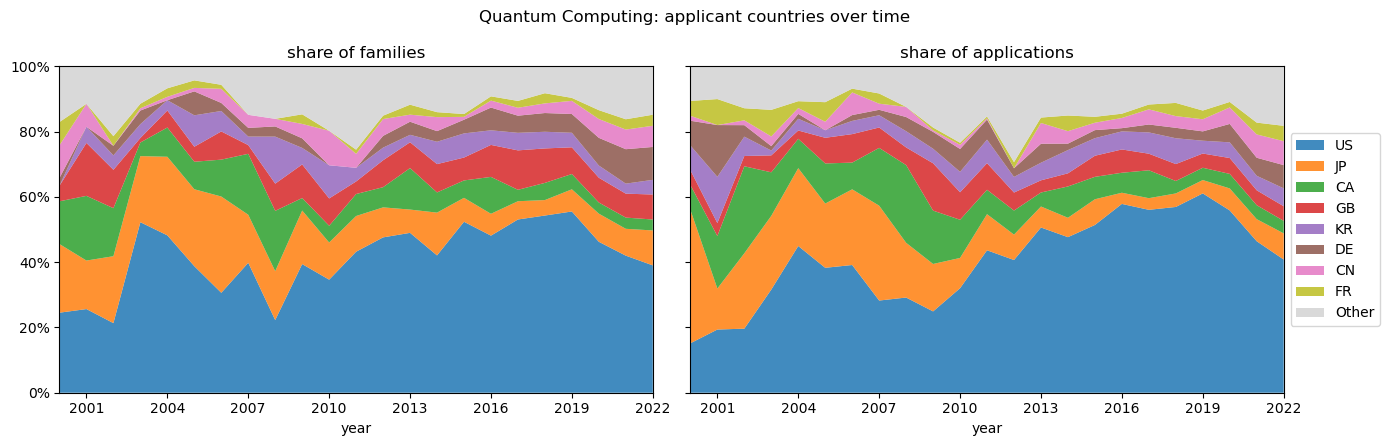

In [27]:
fig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data, "ctry"), "ctry"), f"share of {UNIT_LABEL[level]}")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()